In [92]:
%load_ext autoreload
%autoreload 2
from IPython import get_ipython
get_ipython().run_line_magic('load_ext', 'autoreload')
get_ipython().run_line_magic('autoreload', '2')
import parse_data.prepare_data as prepare_data
import globals
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from plotting import plot_octagon, plot_trajectory
import data_extraction.get_indices as get_indices
import plotting.plot_probability_chose_wall as plot_probability_chose_wall
import plotting.plot_counts_seen_vs_chosen as plot_counts_seen_vs_chosen
import data_strings
import analysis.wall_visibility_and_choice as wall_visibility_and_choice
from scipy.stats import wilcoxon
import data_extraction.data_saving as data_saving
import os
import plotting.plot_boxplots as plot_boxplots
import plotting.plot_violinplots as plot_violinplots

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [93]:
drop_p_choose_high = False
drop_box_plot = False
drop_given_wall_condition = False
drop_ratio_solo_social_plot = False
drop_scatter_plot = False


In [94]:
loading = True

# set True to redo the slow analyses instead of reading the cached results.
# Cached results live outside the repo, in data_strings.ANALYSIS_CACHE_DIR, and are
# recomputed on their own if the number of sessions or the parameters below change.
# data_saving.clear_cache() throws all of them away
recompute = False

### Plot the probability of choosing High across solo and social conditions
Drop points if there are too few trials after filtering the trials list and dropping initial trials

In [95]:
# raw data for direct processing
data_folder = data_strings.DATA_FOLDER
json_filenames_all_social = data_strings.JSON_FILENAMES_SOCIAL
json_filenames_all_solo = data_strings.JSON_FILENAMES_SOLO

# saved pd dataframes of pre-processed data
saved_dataframe_social = data_strings.FILENAME_SOCIAL
saved_dataframe_solo = data_strings.FILENAME_SOLO


In [96]:
if not drop_p_choose_high and not loading:
    _, trial_lists_solo = prepare_data.prepare_data(data_folder, json_filenames_all_solo, combine=False)

elif not drop_p_choose_high and loading:
    trial_lists_solo = data_saving.load_data(saved_dataframe_solo)

In [52]:

if not loading:
    _, trial_lists_social = prepare_data.prepare_data(data_folder, json_filenames_all_social, combine=False)
    trial_lists_social = trial_lists_social

else:
    trial_lists_social = data_saving.load_data(saved_dataframe_social)

In [53]:
# get the probability of choosing the wall for solo and social sessions, with cut_solo_trials trials dropped from the start of the first solo session
if not drop_p_choose_high:
    (probability_choose_high_social_array,
    probability_choose_high_solo_array,
    probability_choose_high_solo_array_first_session,
    probability_choose_high_solo_array_second_session) = data_saving.cached(
        'phigh_solo_social_wallsep4',
        lambda: plot_probability_chose_wall.get_probability_chose_high_solo_social_all_sessions_df(trial_lists_solo,
                                                                                                  trial_lists_social,
                                                                                                  wall_sep=4,
                                                                                                  trial_type=globals.HIGH_LOW,
                                                                                                  cut_solo_trials=5),
        recompute=recompute, stamp=(len(trial_lists_solo), len(trial_lists_social), 4, 5))

phigh_solo_social_wallsep4: not cached, computing
This trial list, player 1 has no wins at High
This trial list, player 1 has no wins at High
phigh_solo_social_wallsep4: computed and cached


In [54]:
probability_choose_high_social_array.shape

(100, 2)

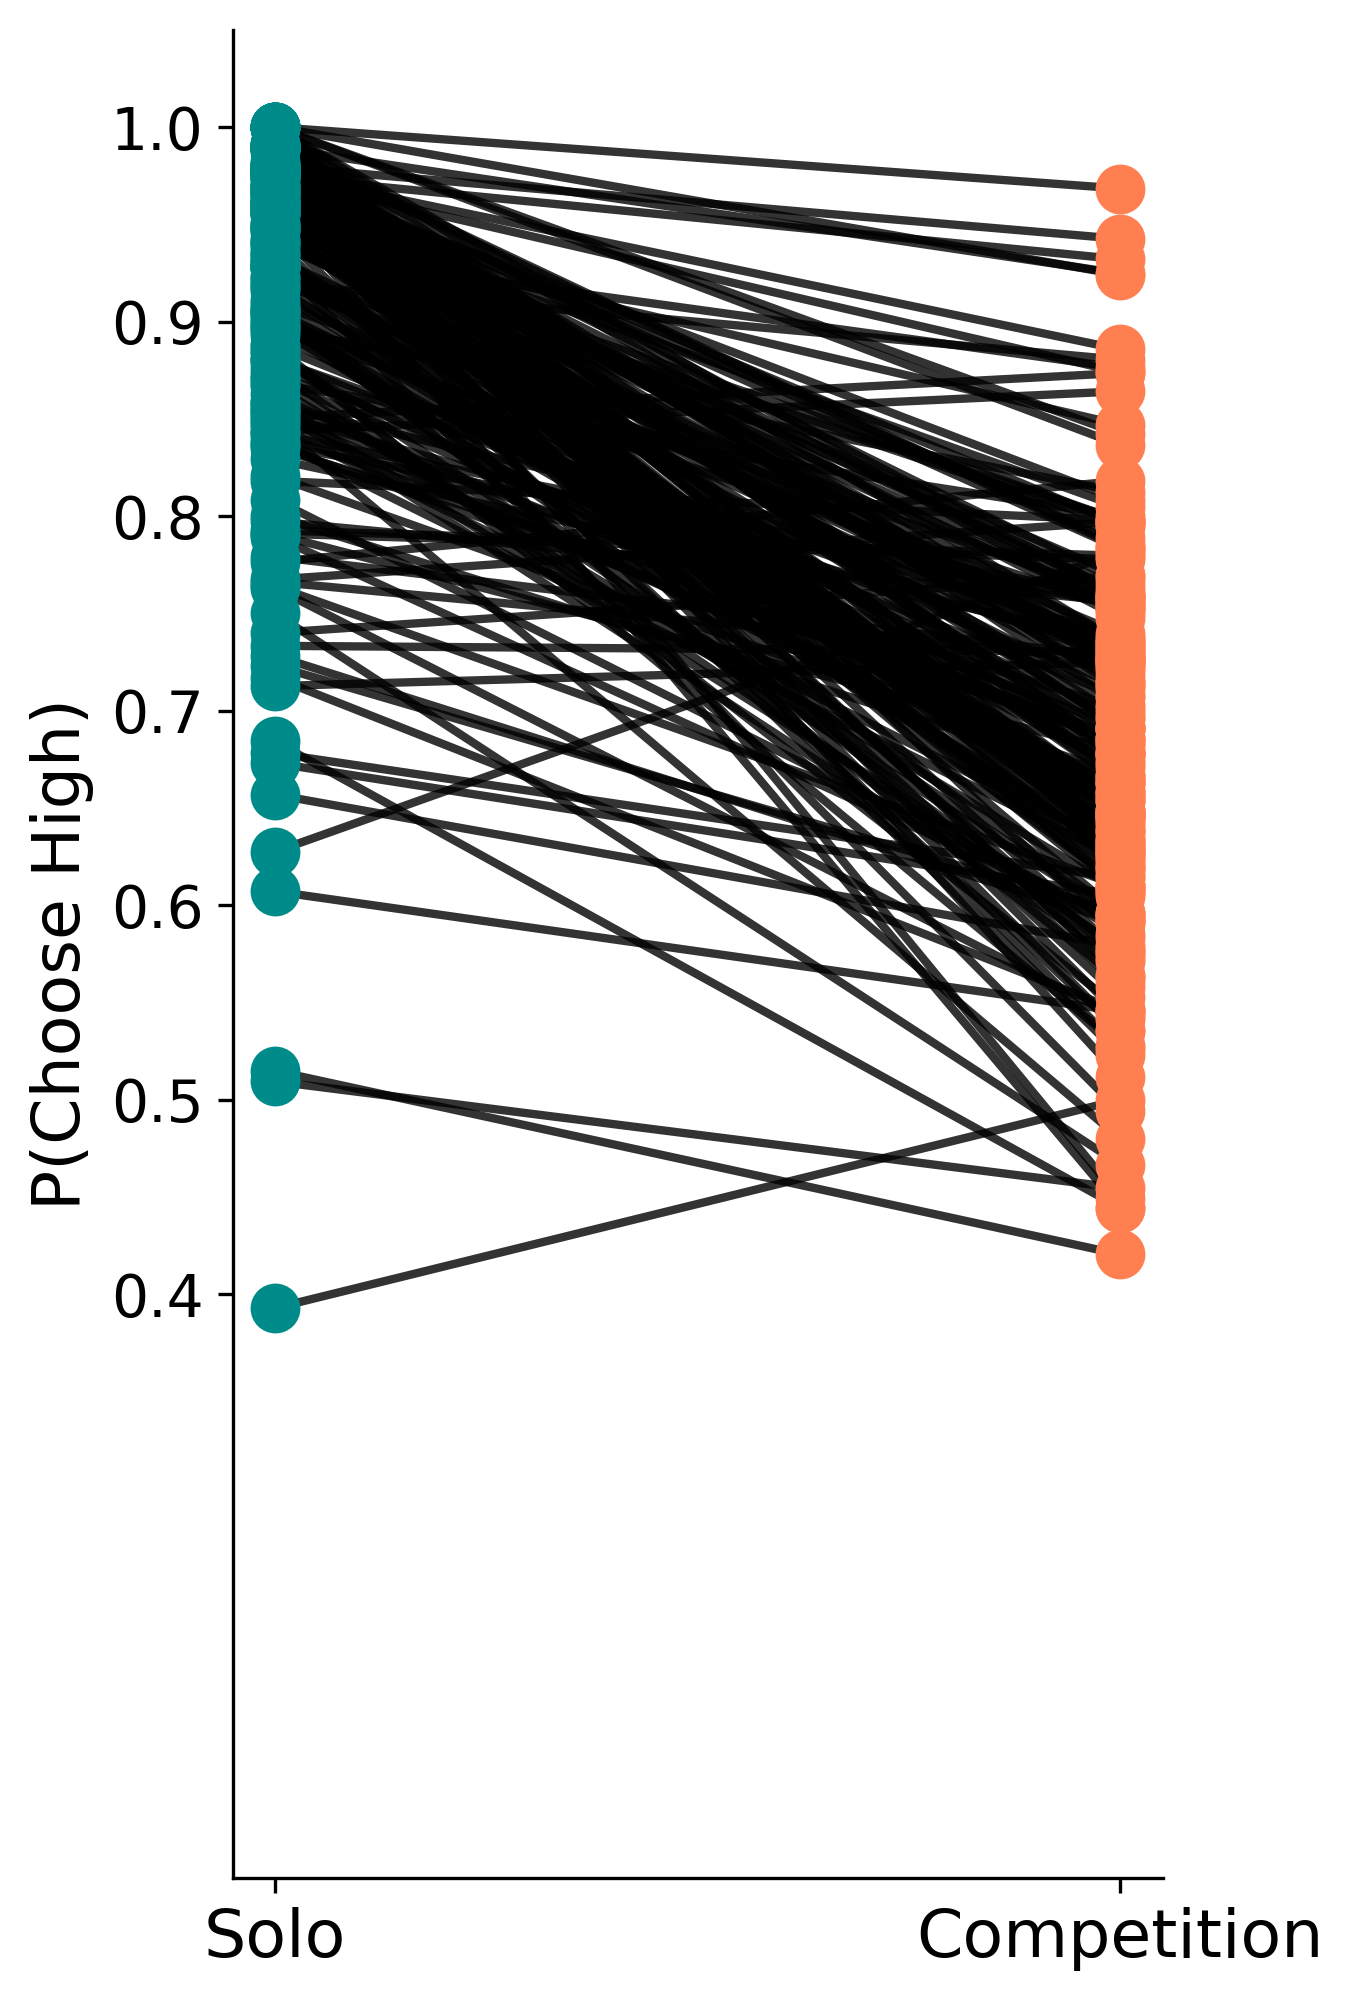

In [97]:
if not drop_p_choose_high:

    plot_probability_chose_wall.plot_probability_choose_high_solo_social(probability_choose_high_social_array, probability_choose_high_solo_array, black_lines=False)

NaN value in probabilities: [       nan 0.54545455 0.4375    ]. Dropping this point from the separated plot.
NaN value in probabilities: [  nan 0.625 0.5  ]. Dropping this point from the separated plot.
NaN value in probabilities: [       nan 0.6        0.76923077]. Dropping this point from the separated plot.
NaN value in probabilities: [0.45454545 1.                nan]. Dropping this point from the separated plot.
NaN value in probabilities: [   nan 0.5625 0.75  ]. Dropping this point from the separated plot.
NaN value in probabilities: [       nan 0.75       0.83333333]. Dropping this point from the separated plot.
NaN value in probabilities: [       nan 0.5        0.83333333]. Dropping this point from the separated plot.
NaN value in probabilities: [1.         0.38095238        nan]. Dropping this point from the separated plot.
NaN value in probabilities: [  nan 0.5   0.875]. Dropping this point from the separated plot.
NaN value in probabilities: [nan 0.5 1. ]. Dropping this poin

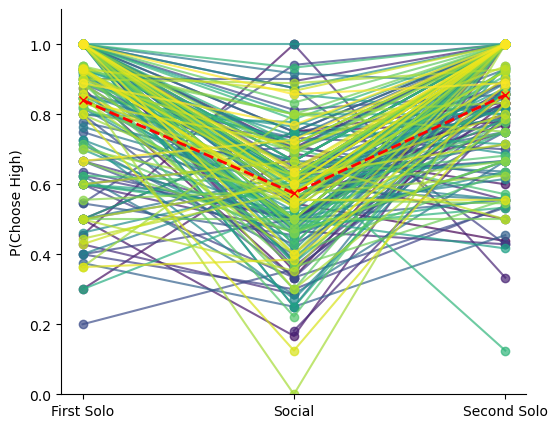

In [56]:
if not drop_p_choose_high:
    plot_probability_chose_wall.plot_probability_choose_high_solo_social(probability_choose_high_social_array, probability_choose_high_solo_array_first_session,
                                                                     probability_choose_high_solo_array_second_session, black_lines=False)

In [57]:
if not drop_p_choose_high:
    ## Testing P(choose High) social and solo data with an independent analysis method to the one above
    probability_choose_high_social_array = data_saving.cached(
        'phigh_social_independent',
        lambda: plot_probability_chose_wall.get_probability_chose_high_social_all_sessions(trial_lists_social,
                                                                                          inferred_choice=True),
        recompute=recompute, stamp=len(trial_lists_social))

    probability_choose_high_solo_array = data_saving.cached(
        'phigh_solo_combined_independent',
        lambda: plot_probability_chose_wall.get_probability_chose_high_solo_all_sessions_combined(trial_lists_solo,
                                                                                                 cut_trials=5,
                                                                                                 data_size_cutoff=6),
        recompute=recompute, stamp=(len(trial_lists_solo), 5, 6))

phigh_social_independent: not cached, computing


/home/tom/repos/octagon_analysis/trajectory_analysis/trajectory_vectors.py:274: RuntimeWarning: invalid value encountered in divide
  cosine_similarities = dot_products / (player_to_alcove_vector_norms_trajectory
/home/tom/repos/octagon_analysis/analysis/loser_inferred_choice.py:47: RuntimeWarning: Mean of empty slice
  return np.argmax(np.nanmean(cosine_similarity_trajectory, axis=1))
/home/tom/repos/octagon_analysis/analysis/loser_inferred_choice.py:149: RuntimeWarning: Mean of empty slice
  highest_alignment_val = np.max(np.nanmean(cosine_similarity_trajectory, axis=1))


phigh_social_independent: computed and cached
phigh_solo_combined_independent: not cached, computing
phigh_solo_combined_independent: computed and cached


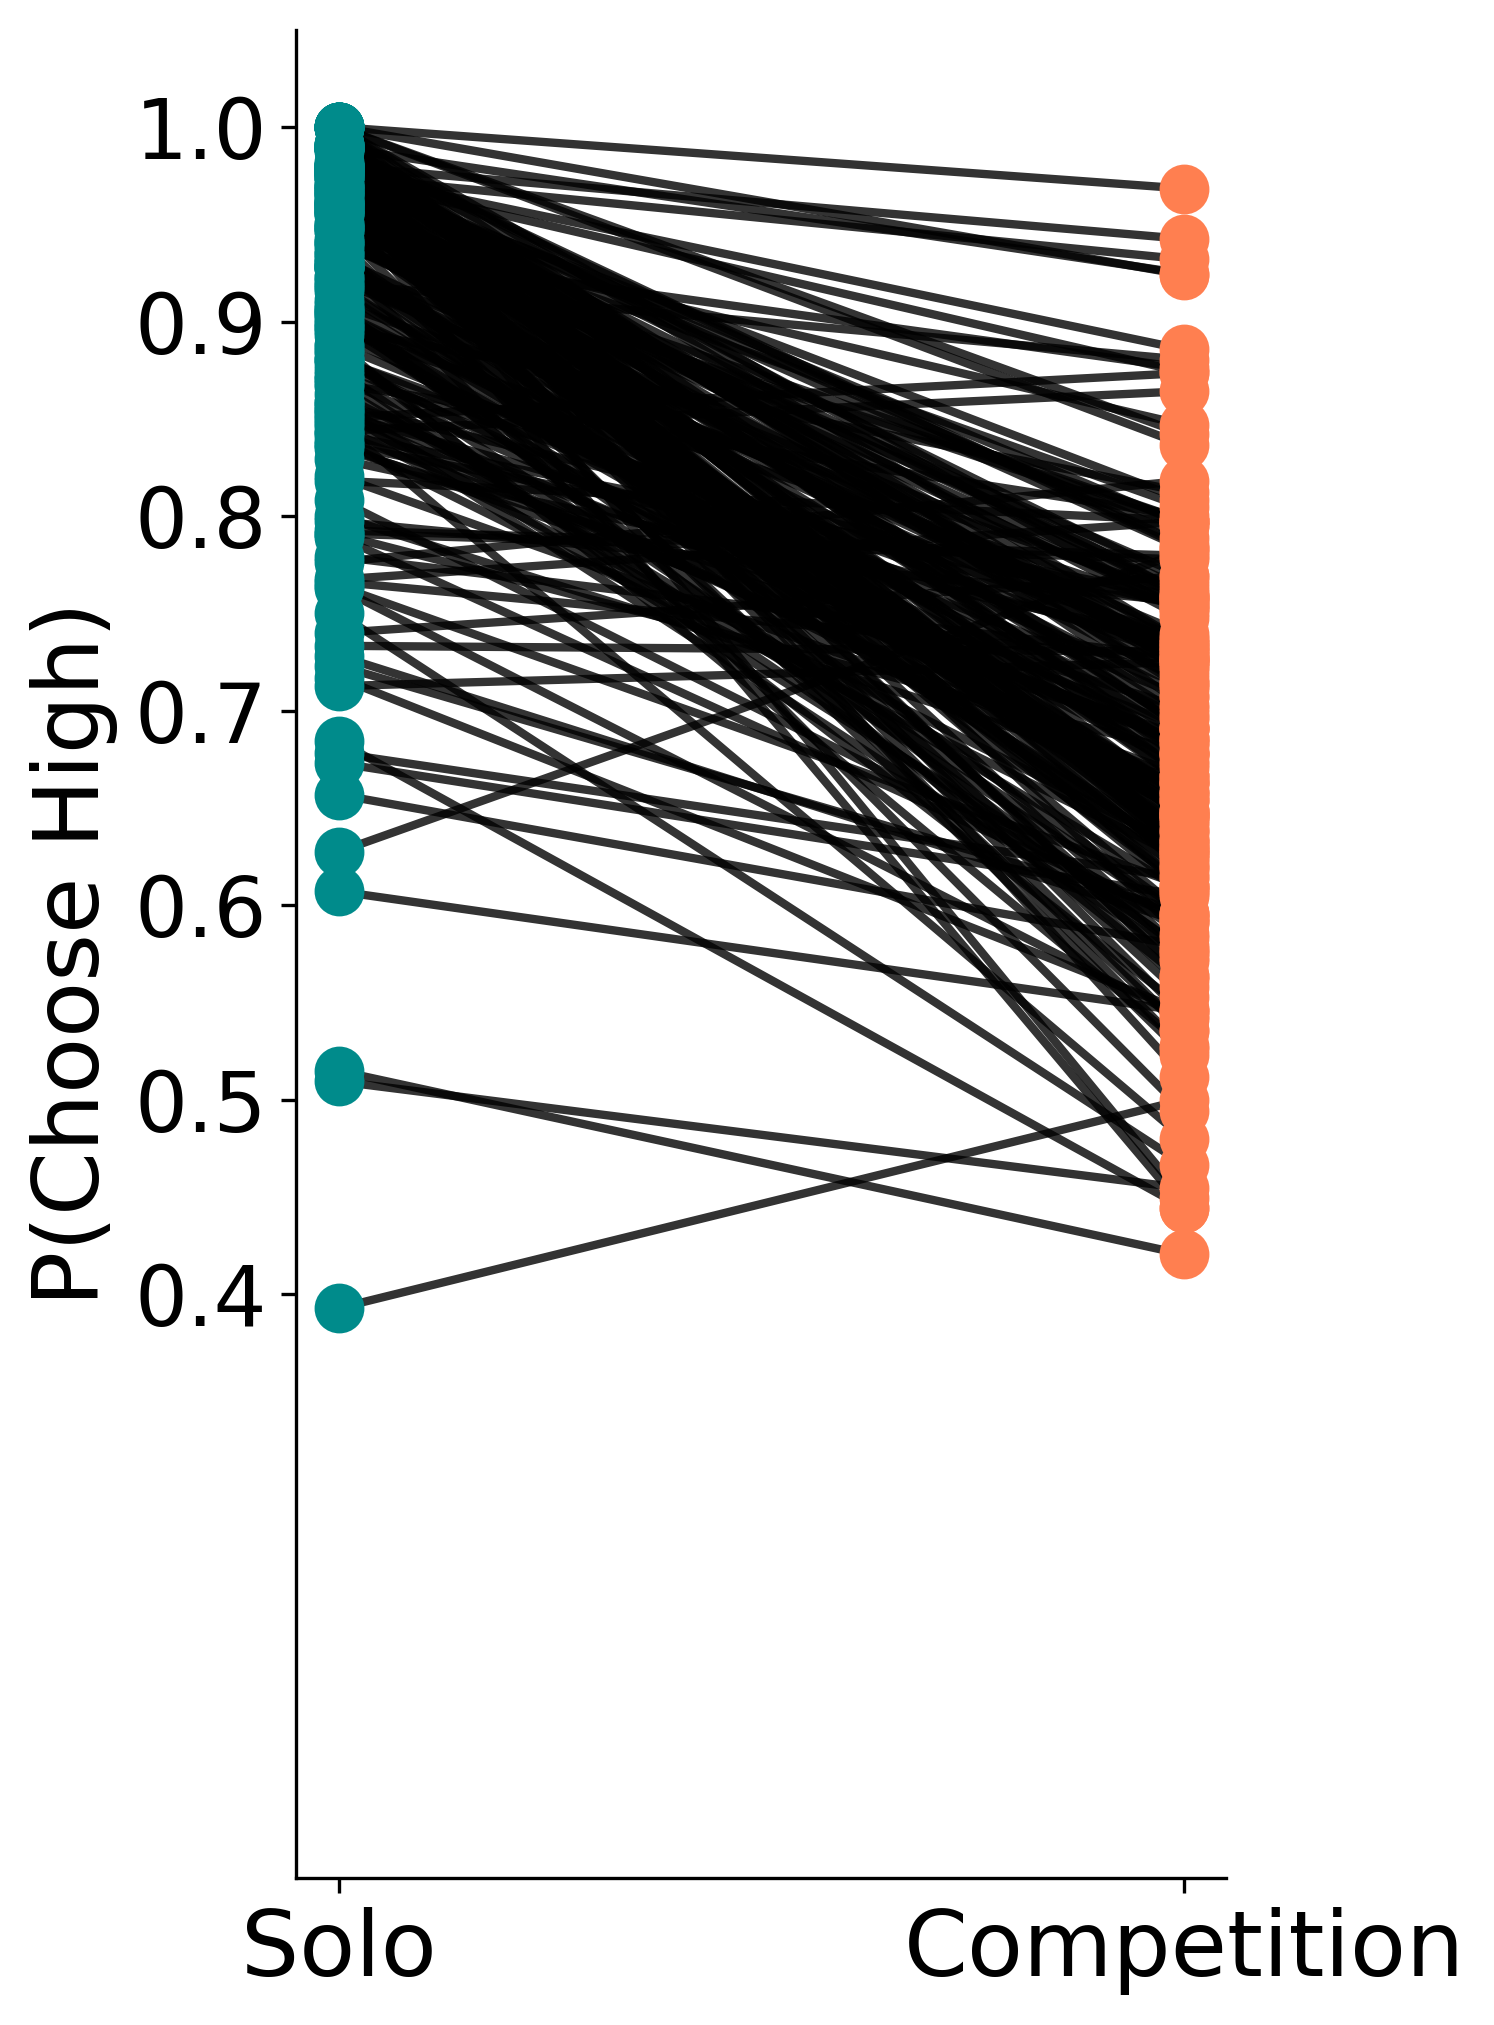

In [58]:
if not drop_p_choose_high:
    plot_probability_chose_wall.plot_probability_choose_high_solo_social(probability_choose_high_social_array, probability_choose_high_solo_array, black_lines=False,
                                                                         fontsize=22)

/home/tom/repos/octagon_analysis/plotting/plot_boxplots.py:78: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x="Condition", y="Probability", data=df, palette=custom_palette, width=.8,


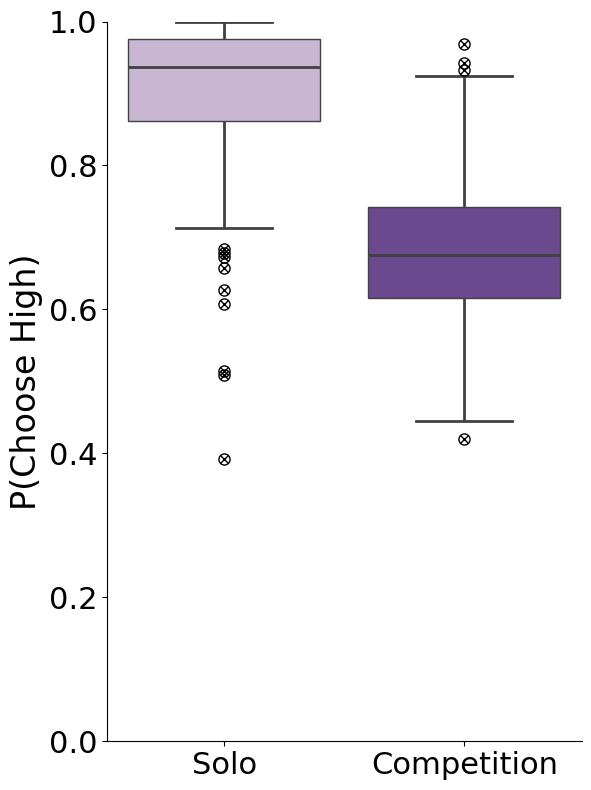

In [59]:
data = [probability_choose_high_solo_array, probability_choose_high_social_array]
labels = ['Solo', 'Competition']
plot_boxplots.plot_boxplot(data, labels, 'P(Choose High)', ylim=[0.0,1], color_offset=8,
                           return_data=False);

/home/tom/repos/octagon_analysis/plotting/plot_violinplots.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(x="Condition", y="Probability", data=df, palette=custom_palette,


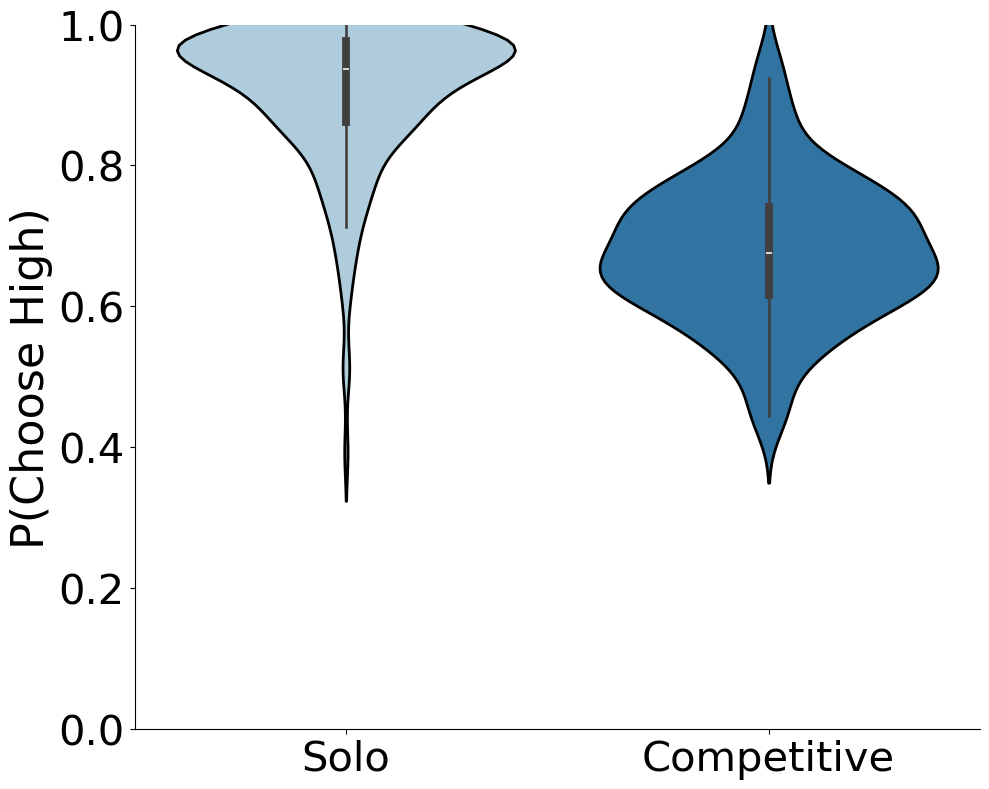

In [60]:
data = [probability_choose_high_solo_array, probability_choose_high_social_array]
labels = ['Solo', 'Competitive']
plot_violinplots.plot_violinplot(data, labels, 'P(Choose High)', ylim=[0.0,1], color_offset=0,
                           return_data=False);

/home/tom/repos/octagon_analysis/plotting/plot_probability_chose_wall.py:120: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x="Condition", y="Probability", data=df, palette=custom_palette, width=.8,


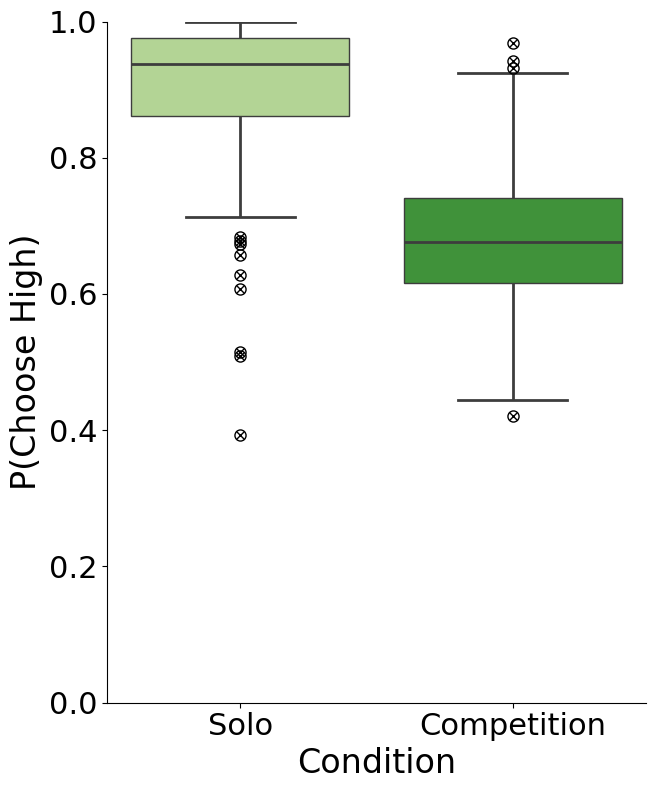

In [61]:
# Create the boxplot with academic poster settings (without paired lines)
plot_probability_chose_wall.boxplot_solo_social_probability(
    solo_probabilities=probability_choose_high_solo_array,
    social_probabilities=probability_choose_high_social_array,
    ylabel="P(Choose High)",
    xlabel="Condition",
    ylim=(0, 1),
    set_aspect=2.5,
    fontsize=24
)

# plt.savefig('solo_vs_competition_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

### Boxplot Visualization Options
Below are two versions of the same boxplot:
1. Standard boxplot (showing medians, quartiles, and outliers as 'x' markers)
2. Paired boxplot (showing the same data but with connecting lines between matched data points)

/home/tom/repos/octagon_analysis/plotting/plot_probability_chose_wall.py:120: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x="Condition", y="Probability", data=df, palette=custom_palette, width=.8,


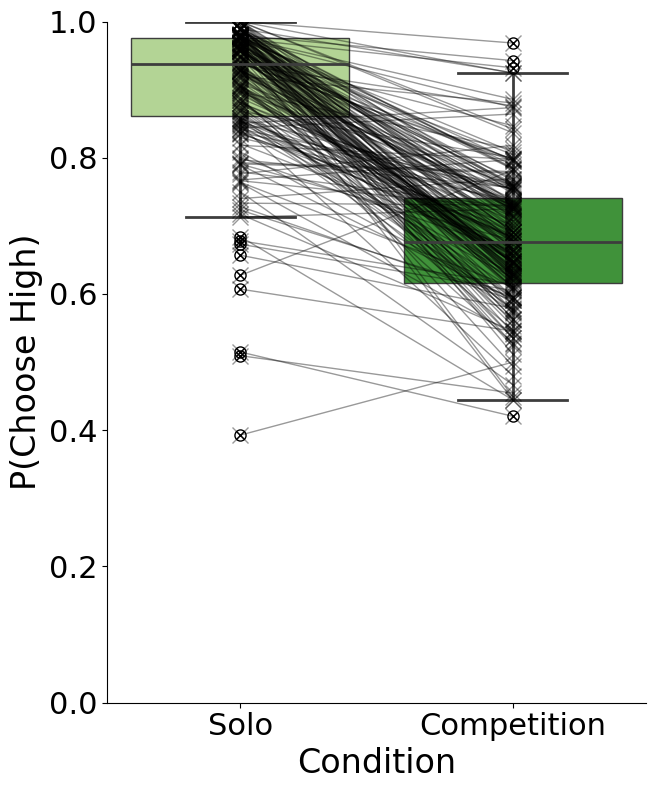

In [62]:
# Create the boxplot with paired lines connecting matching data points
plot_probability_chose_wall.boxplot_solo_social_probability_paired(
    solo_probabilities=probability_choose_high_solo_array,
    social_probabilities=probability_choose_high_social_array,
    ylabel="P(Choose High)",
    xlabel="Condition",
    ylim=(0, 1),
    set_aspect=2.5,
    fontsize=24
)

plt.savefig('solo_vs_competition_paired_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

### Wilcoxon signed rank test for difference between solo and social

In [63]:
phigh_social_wilcoxon

array([0.60493827, 0.64835165, 0.55813953, 0.76923077, 0.66666667,
       0.57534247, 0.62365591, 0.7265625 , 0.54545455, 0.78181818,
       0.79775281, 0.44444444, 0.62650602, 0.72527473, 0.73611111,
       0.69072165, 0.70689655, 0.54320988, 0.78313253, 0.5       ,
       0.54166667, 0.87394958, 0.57746479, 0.78899083, 0.7972973 ,
       0.60714286, 0.88571429, 0.6779661 , 0.67857143, 0.53535354,
       0.75862069, 0.73737374, 0.64556962, 0.66336634, 0.48      ,
       0.54545455, 0.66666667, 0.88043478, 0.67272727, 0.63366337,
       0.87356322, 0.61386139, 0.44444444, 0.86419753, 0.69565217,
       0.79775281, 0.45454545, 0.6097561 , 0.46666667, 0.79569892,
       0.69662921, 0.64835165, 0.77777778, 0.8125    , 0.6375    ,
       0.62886598, 0.73033708, 0.67045455, 0.64634146, 0.62      ,
       0.52777778, 0.72580645, 0.5952381 , 0.7628866 , 0.61904762,
       0.67391304, 0.74766355, 0.61702128, 0.57142857, 0.62650602,
       0.87619048, 0.78378378, 0.56338028, 0.60824742, 0.65789

In [64]:
wilcoxon_nan_mask = ~np.isnan(probability_choose_high_solo_array.ravel()) & ~np.isnan(probability_choose_high_social_array.ravel())
phigh_solo_wilcoxon = probability_choose_high_solo_array.ravel()[wilcoxon_nan_mask]
phigh_social_wilcoxon = probability_choose_high_social_array.ravel()[wilcoxon_nan_mask]

In [65]:
# Perform Wilcoxon signed-rank test
stat, p_value = wilcoxon(phigh_solo_wilcoxon.ravel(), phigh_social_wilcoxon.ravel())

# Print results
print(f"Wilcoxon test statistic: {stat}")
print(f"P-value: {p_value}")

Wilcoxon test statistic: 136.0
P-value: 1.098526152370546e-33


In [66]:
if not drop_p_choose_high:

    trial_lists_filtered = []
    for trial_list in trial_lists_solo:

        trial_list = trial_list[5:]
        
        a = get_indices.get_trials_trialtype(trial_list, trial_type=globals.HIGH_LOW)
        trial_list = [trial_list[i] for i in a]

        b = get_indices.get_trials_with_wall_sep(trial_list, wall_sep=4)
        trial_list = [trial_list[i] for i in b]

        print(len(trial_list))
        trial_lists_filtered.append(trial_list)




    print(f"Sum: {sum(1 for trial_list in trial_lists_filtered if len(trial_list) <= 4)}")
    print(f"Total sum: {len(trial_lists_filtered)}")


4
16
9
5
8
5
8
9
3
8
11
6
0
13
7
15
11
4
10
10
3
16
6
13
1
6
5
6
4
6
5
4
5
6
1
8
4
7
0
6
2
5
4
5
3
9
3
5
5
7
7
3
4
4
1
6
5
4
5
7
2
4
6
7
6
2
7
6
8
5
2
7
12
6
5
7
10
8
15
9
10
10
10
13
5
4
11
7
11
10
11
14
5
5
15
12
5
15
10
4
14
10
9
11
2
9
6
8
12
14
11
9
8
14
14
15
9
8
16
13
18
9
8
11
9
14
9
11
7
13
14
12
24
14
7
15
8
12
15
12
7
9
10
13
14
12
11
13
10
13
8
14
16
12
13
11
6
9
11
18
5
11
17
9
11
9
11
7
11
16
12
15
13
15
7
11
14
8
15
9
10
13
11
12
13
14
11
19
11
16
26
12
11
11
13
11
8
8
9
4
11
13
14
11
13
13
15
16
11
6
13
14
6
7
4
10
10
17
11
12
7
11
11
10
13
13
8
8
14
12
11
10
9
14
8
16
13
16
10
7
14
12
10
12
5
10
10
14
9
11
8
15
4
12
6
9
15
15
17
12
3
8
10
14
13
14
13
13
8
13
10
9
9
7
15
7
11
11
16
14
10
15
12
19
16
15
14
22
10
13
11
12
7
11
7
9
12
6
14
5
8
9
17
11
9
8
10
6
12
10
9
9
14
14
8
12
11
8
9
6
16
11
12
12
13
11
15
13
9
9
14
15
16
12
12
12
9
11
15
11
10
8
11
12
8
10
10
14
8
14
13
15
12
7
16
13
9
13
10
8
10
16
10
10
14
12
7
14
10
9
17
7
15
10
10
12
12
11
14
9
11
7
13
9
14
5
14
5

### Plot the probability of choosing the low wall across different conditions
Inferred losers choice seems to be slow mainly because of get_wall_visible (20-30 ms seconds for each trial for each player)

The main function called in probability_first_wall_chosen_and_low_multiple_sessions_df, first_visible_wall_chosen_session, accounts for basically all of the time in this cell

Within first_visible_wall_chosen_session, it seems to only be get_wall_visible that takes up time on each trial loop 

The main function for inferring losers choice seems to only take about 200 ms per player per session

NB: This means it is not loser's inferred choice but identifying wall visibility (first wall vis, etc.) that is taking time

In [67]:
if not drop_box_plot:
  (probability_first_wall_chosen_when_low_array,
    times_first_wall_chosen_when_low_array,
    probability_first_wall_chosen_array) = data_saving.cached(
      'first_wall_low_social',
      lambda: wall_visibility_and_choice.probability_first_wall_chosen_and_low_multiple_sessions_social(trial_lists_social[:12], wall_sep=None, inferred_choice=False, debug=False),
      recompute=recompute, stamp=(len(trial_lists_social), 12))

  (probability_first_wall_chosen_when_high_array,
    times_first_wall_chosen_when_high_array,
    probability_first_wall_chosen_array) = data_saving.cached(
      'first_wall_high_social',
      lambda: wall_visibility_and_choice.probability_first_wall_chosen_and_low_multiple_sessions_social(trial_lists_social[:12], wall_sep=None, inferred_choice=False, reverse=True, debug=False),
      recompute=recompute, stamp=(len(trial_lists_social), 12))

  wall_choice_probabilities = [probability_first_wall_chosen_array, probability_first_wall_chosen_when_low_array, probability_first_wall_chosen_when_high_array] 
  wall_choice_labels = ['First Wall Seen', 'First Wall Seen (Low)', 'First Wall Seen (High)']

first_wall_low_social: not cached, computing
first_wall_low_social: computed and cached
first_wall_high_social: not cached, computing
first_wall_high_social: computed and cached


In [68]:
if not drop_box_plot:
  (probability_first_wall_chosen_when_low_array,
    times_first_wall_chosen_when_low_array,
    probability_first_wall_chosen_array) = data_saving.cached(
      'first_wall_low_solo',
      lambda: wall_visibility_and_choice.probability_first_wall_chosen_and_low_multiple_sessions_combined_solo(trial_lists_solo, wall_sep=None, debug=False),
      recompute=recompute, stamp=len(trial_lists_solo))

  (probability_first_wall_chosen_when_high_array,
    times_first_wall_chosen_when_high_array,
    probability_first_wall_chosen_array) = data_saving.cached(
      'first_wall_high_solo',
      lambda: wall_visibility_and_choice.probability_first_wall_chosen_and_low_multiple_sessions_combined_solo(trial_lists_solo, wall_sep=None, reverse=True, debug=False),
      recompute=recompute, stamp=len(trial_lists_solo))

  wall_choice_probabilities = [probability_first_wall_chosen_array, probability_first_wall_chosen_when_low_array, probability_first_wall_chosen_when_high_array] 
  wall_choice_labels = ['First Wall Seen', 'First Wall Seen (Low)', 'First Wall Seen (High)']

first_wall_low_solo: not cached, computing
first_wall_low_solo: computed and cached
first_wall_high_solo: not cached, computing
first_wall_high_solo: computed and cached


/home/tom/repos/octagon_analysis/plotting/plot_probability_chose_wall.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Condition", y="Probability", data=df, palette=custom_palette, width=.8)


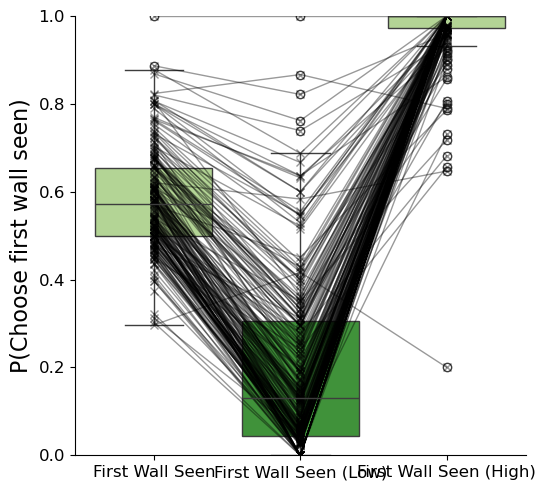

In [69]:
if not drop_box_plot:   
    plot_probability_chose_wall.boxplot_probability_choose_wall(wall_choice_probabilities, wall_choice_labels, ylabel="P(Choose first wall seen)")

Histogram of trial number counts for the current condition, across players

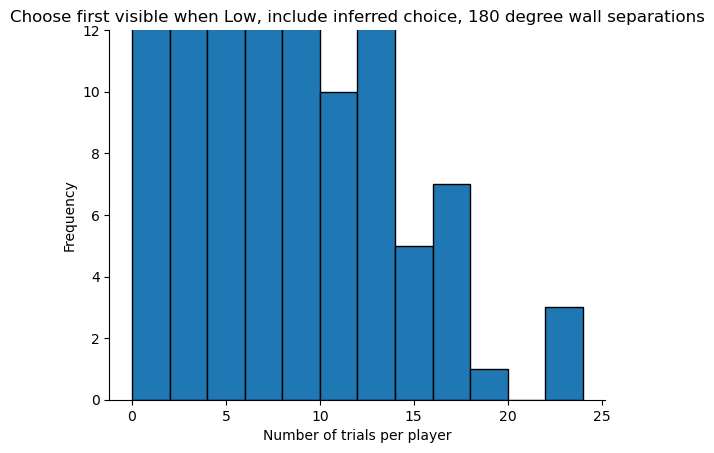

In [70]:
if not drop_box_plot:
    data = times_first_wall_chosen_when_low_array.ravel()
    plt.hist(data, bins=range(0,25,2), edgecolor='black')
    plt.ylim([0, 12])
    plt.title("Choose first visible when Low, include inferred choice, 180 degree wall separations")
    plt.xlabel("Number of trials per player")
    plt.ylabel("Frequency")

    # Remove the top and right spines
    ax = plt.gca()  # Get the current axes
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

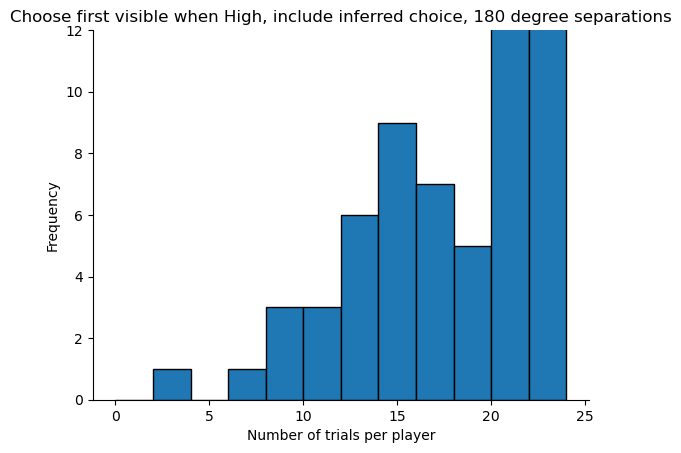

In [71]:
if not drop_box_plot:    
    data = times_first_wall_chosen_when_high_array.ravel()
    plt.hist(data, bins=range(0,25,2), edgecolor='black')
    plt.ylim([0, 12])
    plt.title("Choose first visible when High, include inferred choice, 180 degree separations")
    plt.xlabel("Number of trials per player")
    plt.ylabel("Frequency")

    # Remove the top and right spines
    ax = plt.gca()  # Get the current axes
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

In [72]:
# if not drop_box_plot:
#     data = {
#         'Condition' : times_high_wall_first_seen_and_choice_data.ravel(),
#         'Chosen' : times_high_wall_first_seen_and_chosen.ravel()
#     }

#     plot_counts_seen_vs_chosen.plot_counts_condition_vs_chosen(data, title='Times high wall seen first and chosen across individuals', define_ylim=(0,45))

### Plot P(choose High) for conditions of High first visible and High second visible
- Also includes stacked bar plots of "num condition fulfilled and choice data avaiable" alongide "condition fulfilled and chose given wall"

In [73]:
if not drop_given_wall_condition:  
  (probability_high_wall_chosen_when_first_seen,
    times_high_wall_first_seen,
    times_high_wall_first_seen_and_choice_data,
    times_high_wall_first_seen_and_chosen) = data_saving.cached(
      'high_first_seen_social_12',
      lambda: wall_visibility_and_choice.given_wall_chosen_conditioned_on_visibility_multiple_sessions_social(trial_lists_social[:12], given_wall_first_vis=True,
                                                                                                             given_wall_index=0, wall_sep=None,
                                                                                                             current_fov=110,
                                                                                                             inferred_choice=False, debug=False),
      recompute=recompute, stamp=(len(trial_lists_social), 12, None, 110, False))

high_first_seen_social_12: not cached, computing
high_first_seen_social_12: computed and cached


In [74]:
if not drop_given_wall_condition:  
  (probability_high_wall_chosen_when_second_seen,
    times_high_wall_second_seen,
    times_high_wall_second_seen_and_choice_data,
    times_high_wall_second_seen_and_chosen) = data_saving.cached(
      'high_second_seen_social_12',
      lambda: wall_visibility_and_choice.given_wall_chosen_conditioned_on_visibility_multiple_sessions_social(trial_lists_social[:12], given_wall_first_vis=False,
                                                                                                             given_wall_index=0, wall_sep=2,
                                                                                                             current_fov=110,
                                                                                                             inferred_choice=False, debug=False),
      recompute=recompute, stamp=(len(trial_lists_social), 12, 2, 110, False))

high_second_seen_social_12: not cached, computing
num_valid_trials is zero for this session, returning np.nan for probability
num_valid_trials is zero for this session, returning np.nan for probability
num_valid_trials is zero for this session, returning np.nan for probability
num_valid_trials is zero for this session, returning np.nan for probability
num_valid_trials is zero for this session, returning np.nan for probability
num_valid_trials is zero for this session, returning np.nan for probability
num_valid_trials is zero for this session, returning np.nan for probability
high_second_seen_social_12: computed and cached


In [75]:
if not drop_given_wall_condition: 
    wall_choice_probabilities = [probability_high_wall_chosen_when_first_seen, probability_high_wall_chosen_when_second_seen] 
    wall_choice_labels = ['High first visible', 'High second visible']

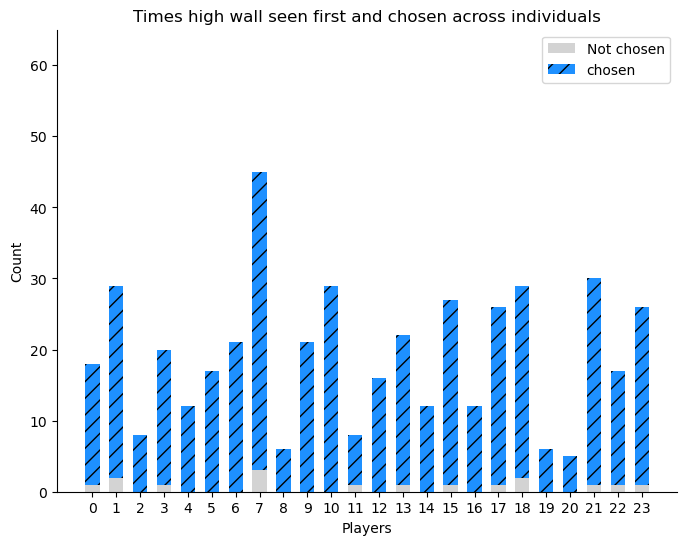

In [76]:
if not drop_given_wall_condition:
    data = {
        'Condition' : times_high_wall_first_seen_and_choice_data.ravel(),
        'Chosen' : times_high_wall_first_seen_and_chosen.ravel()
    }

    plot_counts_seen_vs_chosen.plot_counts_condition_vs_chosen(data, title='Times high wall seen first and chosen across individuals', define_ylim=(0,65))

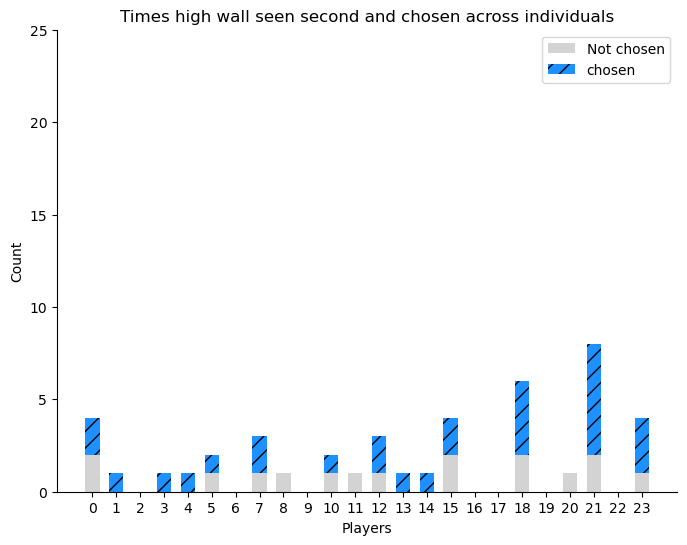

In [77]:
if not drop_given_wall_condition:
    data = {
        'Condition' : times_high_wall_second_seen_and_choice_data.ravel(),
        'Chosen' : times_high_wall_second_seen_and_chosen.ravel()
    }

    plot_counts_seen_vs_chosen.plot_counts_condition_vs_chosen(data, title='Times high wall seen second and chosen across individuals', define_ylim=(0,25))

/home/tom/repos/octagon_analysis/plotting/plot_probability_chose_wall.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Condition", y="Probability", data=df, palette=custom_palette, width=.8)
/home/tom/repos/octagon_analysis/plotting/plot_probability_chose_wall.py:60: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Condition", y="Probability", data=df, palette=custom_palette, width=.8)


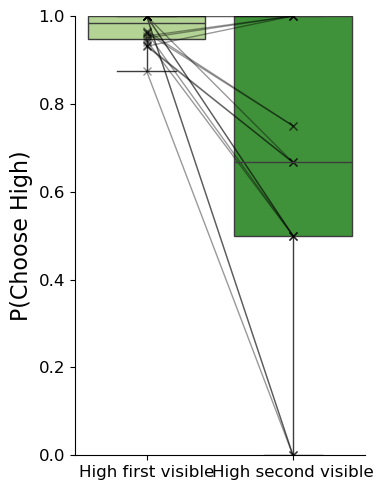

In [78]:
if not drop_given_wall_condition:   
    plot_probability_chose_wall.boxplot_probability_choose_wall(wall_choice_probabilities, wall_choice_labels, ylabel="P(Choose High)")


### Plot of ratio of P(choose High) for conditions of High first visible and High second visible, across solo (combined) and social sessions


First get the standard P(choose High) for High first vis and High second vis conditions

In [79]:
# parameters for this plot
trial_lists_social_ratio_plot = trial_lists_social
trial_lists_solo_ratio_plot = trial_lists_solo
given_wall_first_vis = True
given_wall_index = 0
wall_sep = None
current_fov = 110
cut_trials = 5
inferred_choice = True
debug = False

In [80]:
if not drop_ratio_solo_social_plot:  
  (probability_high_wall_chosen_when_first_seen,
    times_high_wall_first_seen,
    times_high_wall_first_seen_and_choice_data,
    times_high_wall_first_seen_and_chosen) = data_saving.cached(
      'ratio_high_first_seen_social',
      lambda: wall_visibility_and_choice.given_wall_chosen_conditioned_on_visibility_multiple_sessions_social(trial_lists_social_ratio_plot, given_wall_first_vis=True,
                                                                                                             given_wall_index=given_wall_index, wall_sep=wall_sep,
                                                                                                             current_fov=current_fov,
                                                                                                             inferred_choice=inferred_choice, debug=debug),
      recompute=recompute, stamp=(len(trial_lists_social_ratio_plot), given_wall_index, wall_sep, current_fov, inferred_choice))

if not drop_given_wall_condition:  
  (probability_high_wall_chosen_when_second_seen,
    times_high_wall_second_seen,
    times_high_wall_second_seen_and_choice_data,
    times_high_wall_second_seen_and_chosen) = data_saving.cached(
      'ratio_high_second_seen_social',
      lambda: wall_visibility_and_choice.given_wall_chosen_conditioned_on_visibility_multiple_sessions_social(trial_lists_social_ratio_plot, given_wall_first_vis=False,
                                                                                                             given_wall_index=given_wall_index, wall_sep=wall_sep,
                                                                                                             current_fov=current_fov,
                                                                                                             inferred_choice=inferred_choice, debug=debug),
      recompute=recompute, stamp=(len(trial_lists_social_ratio_plot), given_wall_index, wall_sep, current_fov, inferred_choice))

ratio_high_first_seen_social: not cached, computing


/home/tom/repos/octagon_analysis/trajectory_analysis/trajectory_vectors.py:274: RuntimeWarning: invalid value encountered in divide
  cosine_similarities = dot_products / (player_to_alcove_vector_norms_trajectory
/home/tom/repos/octagon_analysis/analysis/loser_inferred_choice.py:47: RuntimeWarning: Mean of empty slice
  return np.argmax(np.nanmean(cosine_similarity_trajectory, axis=1))
/home/tom/repos/octagon_analysis/analysis/loser_inferred_choice.py:149: RuntimeWarning: Mean of empty slice
  highest_alignment_val = np.max(np.nanmean(cosine_similarity_trajectory, axis=1))


ratio_high_first_seen_social: computed and cached
ratio_high_second_seen_social: not cached, computing
num_valid_trials is zero for this session, returning np.nan for probability
num_valid_trials is zero for this session, returning np.nan for probability
ratio_high_second_seen_social: computed and cached


/home/tom/repos/octagon_analysis/plotting/plot_probability_chose_wall.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Condition", y="Probability", data=df, palette=custom_palette, width=.8)
/home/tom/repos/octagon_analysis/plotting/plot_probability_chose_wall.py:60: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Condition", y="Probability", data=df, palette=custom_palette, width=.8)


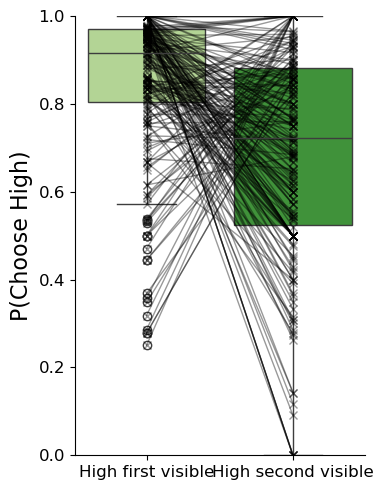

In [81]:
if not drop_ratio_solo_social_plot:   
    wall_choice_probabilities = [probability_high_wall_chosen_when_first_seen, probability_high_wall_chosen_when_second_seen] 
    wall_choice_labels = ['High first visible', 'High second visible']
    plot_probability_chose_wall.boxplot_probability_choose_wall(wall_choice_probabilities, wall_choice_labels, ylabel="P(Choose High)")


Then repeat for solo (combined, drop 5 of first solo)

In [82]:
if not drop_ratio_solo_social_plot:  
  (probability_high_wall_chosen_when_first_seen_solo,
    times_high_wall_first_seen_solo,
    times_high_wall_first_seen_and_choice_data_solo,
    times_high_wall_first_seen_and_chosen_solo) = data_saving.cached(
      'ratio_high_first_seen_solo',
      lambda: wall_visibility_and_choice.given_wall_chosen_conditioned_on_visibility_multiple_sessions_solo(trial_lists_solo_ratio_plot, given_wall_first_vis=True,
                                                                                                           given_wall_index=given_wall_index, wall_sep=wall_sep,
                                                                                                           current_fov=current_fov, cut_trials=cut_trials,
                                                                                                           inferred_choice=False, debug=debug),
      recompute=recompute, stamp=(len(trial_lists_solo_ratio_plot), given_wall_index, wall_sep, current_fov, cut_trials))

if not drop_given_wall_condition:  
  (probability_high_wall_chosen_when_second_seen_solo,
    times_high_wall_second_seen_solo,
    times_high_wall_second_seen_and_choice_data_solo,
    times_high_wall_second_seen_and_chosen_solo) = data_saving.cached(
      'ratio_high_second_seen_solo',
      lambda: wall_visibility_and_choice.given_wall_chosen_conditioned_on_visibility_multiple_sessions_solo(trial_lists_solo_ratio_plot, given_wall_first_vis=False,
                                                                                                           given_wall_index=given_wall_index, wall_sep=wall_sep,
                                                                                                           current_fov=current_fov, cut_trials=cut_trials,
                                                                                                           inferred_choice=False, debug=debug),
      recompute=recompute, stamp=(len(trial_lists_solo_ratio_plot), given_wall_index, wall_sep, current_fov, cut_trials))

ratio_high_first_seen_solo: not cached, computing
ratio_high_first_seen_solo: computed and cached
ratio_high_second_seen_solo: not cached, computing
ratio_high_second_seen_solo: computed and cached


/home/tom/repos/octagon_analysis/plotting/plot_probability_chose_wall.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Condition", y="Probability", data=df, palette=custom_palette, width=.8)
/home/tom/repos/octagon_analysis/plotting/plot_probability_chose_wall.py:60: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Condition", y="Probability", data=df, palette=custom_palette, width=.8)


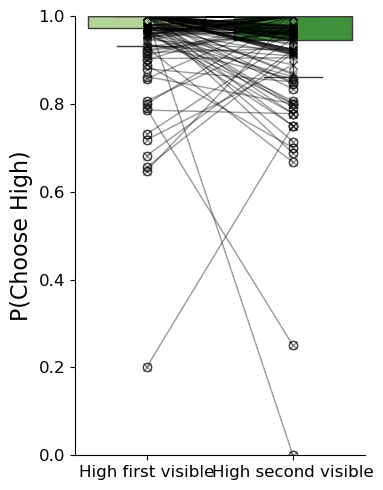

In [83]:
if not drop_ratio_solo_social_plot:   
    wall_choice_probabilities = [probability_high_wall_chosen_when_first_seen_solo, probability_high_wall_chosen_when_second_seen_solo] 
    wall_choice_labels = ['High first visible', 'High second visible']
    plot_probability_chose_wall.boxplot_probability_choose_wall(wall_choice_probabilities, wall_choice_labels, ylabel="P(Choose High)")


Now we have the data, get the ratios between first and second seen for each condition

In [84]:
probability_high_wall_chosen_when_first_seen_solo, probability_high_wall_chosen_when_first_seen.ravel()

(array([1.        , 0.94444444, 1.        , 0.96      , 1.        ,
        1.        , 1.        , 1.        , 0.64705882, 0.9375    ,
        0.90322581, 1.        , 1.        , 1.        , 0.85714286,
        1.        , 1.        , 1.        , 1.        , 1.        ,
        0.92857143, 1.        , 1.        , 0.95652174, 1.        ,
        0.95238095, 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.        , 1.        , 0.9       , 0.8       ,
        1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 0.96296296, 0.88888889, 1.        , 1.        ,
        0.93333333, 0.78947368, 1.        , 1.        , 1.        ,
        1.        , 1.        , 0.68181818, 1.        , 1.        ,
        1.        , 0.71794872, 1.        , 0.93103448, 1.        ,
        0.73076923, 0.96      , 0.95348837, 1.        , 1.        ,
        1.        , 1.        , 0.96969697, 0.97560976, 1.        ,
        0.95833333, 1.        , 1.        , 1.  

In [85]:
probability_high_wall_chosen_when_second_seen_solo, probability_high_wall_chosen_when_second_seen.ravel()

(array([0.83333333, 1.        , 0.96      , 0.88888889, 1.        ,
        1.        , 0.92307692, 0.79166667, 1.        , 0.85714286,
        0.9047619 , 1.        , 0.92307692, 0.94444444, 1.        ,
        1.        , 0.91666667, 1.        , 1.        , 0.        ,
        0.66666667, 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.        , 1.        , 0.8       , 1.        ,
        1.        , 1.        , 1.        , 1.        , 1.        ,
        0.6875    , 1.        , 1.        , 1.        , 1.        ,
        0.95238095, 0.77777778, 0.7       , 1.        , 1.        ,
        0.90909091, 0.25      , 1.        , 1.        , 1.        ,
        1.        , 0.97560976, 0.92307692, 1.        , 0.91304348,
        1.        , 0.88888889, 1.        , 0.96153846, 1.        ,
        0.94871795, 1.        , 0.96774194, 1.        , 1.        ,
        1.        , 1.        , 0.95652174, 0.9375    , 0.92307692,
        1.        , 1.        , 0.96666667, 1.  

In [86]:
times_high_wall_second_seen_and_chosen

array([[ 7.,  8.],
       [ 0., 15.],
       [ 8.,  3.],
       [10., 18.],
       [ 1.,  5.],
       [13.,  1.],
       [13., 15.],
       [ 8., 12.],
       [ 3.,  5.],
       [21.,  0.],
       [ 0., 40.],
       [ 0., 22.],
       [15.,  6.],
       [13.,  1.],
       [ 6., 10.],
       [13., 16.],
       [10., 23.],
       [16.,  9.],
       [ 9., 23.],
       [ 4., 17.],
       [21., 14.],
       [ 1., 20.],
       [ 8., 22.],
       [ 2.,  3.],
       [ 2., 17.],
       [ 9., 19.],
       [ 2., 17.],
       [10.,  9.],
       [14., 16.],
       [ 4., 16.],
       [22.,  3.],
       [ 6., 18.],
       [17., 13.],
       [17.,  4.],
       [ 4., 18.],
       [27., 16.],
       [ 2.,  9.],
       [10., 21.],
       [ 9., 12.],
       [ 5., 14.],
       [18., 12.],
       [11.,  7.],
       [15., 13.],
       [15., 23.],
       [ 6.,  8.],
       [ 7.,  9.],
       [ 7., 37.],
       [10., 15.],
       [26.,  6.],
       [17., 10.],
       [10., 13.],
       [ 7.,  9.],
       [27.,

In [87]:
ratio_solo = probability_high_wall_chosen_when_first_seen_solo/probability_high_wall_chosen_when_second_seen_solo

ratio_social = probability_high_wall_chosen_when_first_seen/probability_high_wall_chosen_when_second_seen

/tmp/ipykernel_1102953/1837245122.py:1: RuntimeWarning: divide by zero encountered in divide
  ratio_solo = probability_high_wall_chosen_when_first_seen_solo/probability_high_wall_chosen_when_second_seen_solo
/tmp/ipykernel_1102953/1837245122.py:3: RuntimeWarning: divide by zero encountered in divide
  ratio_social = probability_high_wall_chosen_when_first_seen/probability_high_wall_chosen_when_second_seen


In [88]:
ratio_solo, ratio_social 

(array([1.2       , 0.94444444, 1.04166667, 1.08      , 1.        ,
        1.        , 1.08333333, 1.26315789, 0.64705882, 1.09375   ,
        0.99830221, 1.        , 1.08333333, 1.05882353, 0.85714286,
        1.        , 1.09090909, 1.        , 1.        ,        inf,
        1.39285714, 1.        , 1.        , 0.95652174, 1.        ,
        0.95238095, 1.        , 1.        , 1.25      , 1.        ,
        1.        , 1.        , 1.        , 0.9       , 0.8       ,
        1.45454545, 1.        , 1.        , 1.        , 1.        ,
        1.05      , 1.23809524, 1.26984127, 1.        , 1.        ,
        1.02666667, 3.15789474, 1.        , 1.        , 1.        ,
        1.        , 1.025     , 0.73863636, 1.        , 1.0952381 ,
        1.        , 0.80769231, 1.        , 0.96827586, 1.        ,
        0.77027027, 0.96      , 0.98527132, 1.        , 1.        ,
        1.        , 1.        , 1.0137741 , 1.04065041, 1.08333333,
        0.95833333, 1.        , 1.03448276, 1.  

/home/tom/repos/octagon_analysis/plotting/plot_probability_chose_wall.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Condition", y="Probability", data=df, palette=custom_palette, width=.8)
/home/tom/repos/octagon_analysis/plotting/plot_probability_chose_wall.py:60: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Condition", y="Probability", data=df, palette=custom_palette, width=.8)


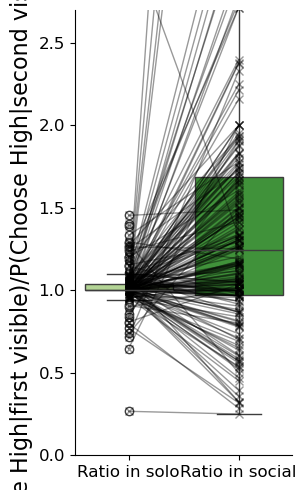

In [89]:
if not drop_ratio_solo_social_plot:   
    wall_choice_probabilities = [ratio_solo, ratio_social] 
    wall_choice_labels = ['Ratio in solo', 'Ratio in social']
    plot_probability_chose_wall.boxplot_probability_choose_wall(wall_choice_probabilities, wall_choice_labels, ylabel="P(Choose High|first visible)/P(Choose High|second visible) ratio",
                                                                 ylim=(0,2.7), set_aspect=1.5)


### Plot performance against probability of choosing Low when Low first visibile 

In [90]:
trial_lists_social_drop_5 = [trial_list for i,trial_list in enumerate(trial_lists_social) if i != 5]

Probability low when first visible: 
 [[0.71428571 0.76190476]
 [1.         0.42857143]
 [0.6        0.875     ]
 [0.78947368 0.65517241]
 [0.85714286 0.81818182]
 [0.6        0.90909091]
 [0.61904762 0.41666667]
 [0.58823529 0.69230769]
 [1.         0.9       ]
 [0.46428571 1.        ]
 [1.         0.27272727]
 [1.         0.46153846]
 [0.58333333 0.72727273]
 [0.23076923 1.        ]
 [0.85714286 0.82758621]
 [0.6        0.70588235]
 [0.70588235 0.33333333]
 [0.4        0.64285714]
 [0.77777778 0.27272727]
 [0.625      0.23809524]
 [0.38461538 0.61904762]
 [1.         0.16666667]
 [0.72222222 0.05      ]
 [0.94444444 0.88888889]
 [0.83333333 0.2173913 ]
 [0.83333333 0.40909091]
 [0.5        0.46428571]
 [0.52941176 0.75      ]
 [0.47826087 0.46153846]
 [0.875      0.07692308]
 [0.125      0.8       ]
 [0.85       0.47368421]
 [0.31578947 0.        ]
 [0.62068966 0.9       ]
 [0.89473684 0.18181818]
 [0.25       0.5       ]
 [0.85714286 0.78571429]
 [0.6        0.09090909]
 [0.76190476

/home/tom/repos/octagon_analysis/plotting/plot_probability_chose_wall.py:314: RuntimeWarning: divide by zero encountered in divide
  ratio_probability_low_when_first_visible = probability_low_when_first_visible[:,0]/probability_low_when_first_visible[:,1]
/home/tom/miniconda3/envs/octagon_analysis/lib/python3.12/site-packages/numpy/lib/_polynomial_impl.py:665: RuntimeWarning: invalid value encountered in divide
  lhs /= scale


LinAlgError: SVD did not converge in Linear Least Squares

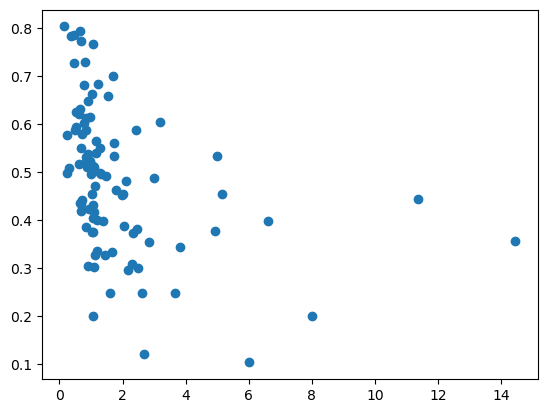

In [91]:
if not drop_scatter_plot:
    plot_probability_chose_wall.plot_performance_against_probability_low_when_first_visible_df(trial_lists_social, inferred_choice=False, correlation_line=True, print_correlation=True)